In [31]:
import pandas as pd
from scipy.stats import chi2_contingency, f_oneway, t,ttest_ind
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest


In [3]:
# load the data
hillstrom = pd.read_csv('data/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv')

hillstrom.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


The documentation for the dataset can be found at [minthatdata analytics website](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html)

The dataset's columns:
    Recency: Months since last purchase.
    History_Segment: Categorization of dollars spent in the past year.
    History: Actual dollar value spent in the past year.
    Mens: 1/0 indicator, 1 = customer purchased Mens merchandise in the past year.
    Womens: 1/0 indicator, 1 = customer purchased Womens merchandise in the past year.
    Zip_Code: Classifies zip code as Urban, Suburban, or Rural.
    Newbie: 1/0 indicator, 1 = New customer in the past twelve months.
    Channel: Describes the channels the customer purchased from in the past year.

Another variable describes the e-mail campaign the customer received:

    Segment
        Mens E-Mail
        Womens E-Mail
        No E-Mail

Finally, we have a series of variables describing activity in the two weeks following delivery of the e-mail campaign:
    Visit: 1/0 indicator, 1 = Customer visited website in the following two weeks.
    Conversion: 1/0 indicator, 1 = Customer purchased merchandise in the following two weeks.
    Spend: Actual dollars spent in the following two weeks.

Customers were randomly split into 3 groups:
1. Men’s email arm: received an email featuring men’s merchandise
2. Women’s email arm: received an email featuring women’s merchandise
3. No email arm (control): received nothing

An A/B test has two arms (A and B). This one is an A/B/C test, so it has three. The control arm is the baseline you compare the others against.

In the data, the arm is stored in one column called segment. Each row is a customer, and that column tells you which group they were in.

In [4]:
# how many customers are in each arm
hillstrom['segment'].value_counts() # Just a slight variation but pretty much balanced.

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

In [5]:
# the outcome targets - spend and visit
hillstrom['visit'].value_counts(normalize=True) * 100


visit
0    85.321875
1    14.678125
Name: proportion, dtype: float64

In [6]:
hillstrom['spend'].describe()

# how many customers spent 0
spent_zero = hillstrom[hillstrom['spend']==0].count()

spent = hillstrom[hillstrom['spend'] > 0].count()

print('Spent nothing:',spent_zero['spend'])
print('Spent:', spent['spend'])

Spent nothing: 63422
Spent: 578


## Confirm randomization
The covariates (recency, history, channel, and the other columns) were measured before anyone got an email. So, if the assignments were truly random the 3 aem shouls look like the same kind of customers on every one of them.

To confirm this, I will create a table of means and proportions.

In [7]:
hillstrom.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


In [8]:
# group by segment

# numerical columns
hillstrom.groupby('segment')[['recency', 'history']].agg(['mean', 'std', 'count'])

recency                      history                   
                   mean       std  count        mean         std  count
segment                                                                
Mens E-Mail    5.773642  3.513350  21307  242.835931  260.355685  21307
No E-Mail      5.749695  3.497517  21306  240.882653  252.739362  21306
Womens E-Mail  5.767850  3.511989  21387  242.536633  255.332880  21387

In [9]:
# share of each category by within each arm
pd.crosstab(hillstrom['segment'], hillstrom['newbie'])
pd.crosstab(hillstrom['segment'], hillstrom['channel'])
pd.crosstab(hillstrom['segment'], hillstrom['history_segment'])
pd.crosstab(hillstrom['segment'], hillstrom['zip_code'])
pd.crosstab(hillstrom['segment'], hillstrom['mens'])
pd.crosstab(hillstrom['segment'], hillstrom['womens'])

womens,0,1
segment,,
Mens E-Mail,9558,11749
No E-Mail,9638,11668
Womens E-Mail,9622,11765


The distribution seems similar looking at it but will use chi-square test to confirm that customer characteristics are similar across the 3 marketing groups.

$H_0$ There's no association between the customer's segment and their assignment marketing group
$H_1$ Theres an association between the customer's segment and their assignment marketing group.

if p_value > 0.05, we fail to reject the null hypothesis.

If there's a possible imbalance, I'll also use cramer's V to measure how strong the association is.
  | Cramér's V | Interpretation |
|---|---|
| 0 | No association |
| 0.1 | Weak association |
| 0.2 | Moderate association |
| 0.3 | Relatively strong association |
| 0.5 | Strong association |
| 1.0 | Perfect association |

In [10]:
categorical_features = [
    'newbie',
    'channel',
    'zip_code',
    'mens',
    'womens'
]

def cramers_v(contingency_table):
    chi2 = chi2_contingency(contingency_table)[0]
    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    return np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )
chi_results = []
for feature in categorical_features:

    # create contingency table
    contingency_table = pd.crosstab(
        hillstrom['segment'],
        hillstrom[feature]
    )

    # chi-square test
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    cramers_v_val = None
    if p_value < 0.05:
        # check strength of association
        cramers_v_val = cramers_v(contingency_table)        

    chi_results.append(
            {'feature': feature,
             'test': 'chi2',
            'statistic': chi2,
            'p_value': p_value,
            'outcome': (
                'No significant difference'
                if p_value > 0.05
                else 'Significant difference'
            ),

            'cramers_v_value': cramers_v_val
            }
        )
    
chi_results_df = pd.DataFrame(chi_results)
chi_results_df
# also measuring the strength of accociation using Cramer's V



,feature,test,statistic,p_value,outcome,cramers_v_value
0,newbie,chi2,0.136868,0.933855,No significant difference,None
1,channel,chi2,3.632402,0.458034,No significant difference,None
2,zip_code,chi2,2.871942,0.579479,No significant difference,None
3,mens,chi2,0.795994,0.671664,No significant difference,None
4,womens,chi2,0.632522,0.728869,No significant difference,None


Using ANOVA to check whether the means of the numerical features within the 3 groups are statistically different

$H_0$: The means are equal across all 3 groups
$H_1$: At-lease one groups average is different.

It calculates an f-statistic by comparing the variation between the group beans with the variation within each group.
* If the group means are close together relative to the variation within each group, the F-statistic will be small.
* If the group means are far apart relative to the variation within each group, the F-statistic will be large.

$F = \frac{\text{between-group variation}}{\text{within-group variation}}$

In [11]:
# Calculating anova
numerical_features = ['recency', 'history']

groups = hillstrom['segment'].unique()

results = []

for feature in numerical_features:

    samples = [hillstrom.loc[hillstrom['segment'] == group, feature].dropna() for group in groups]

    # one way anova
    f_stat, anova_p = f_oneway(*samples)
    results.append(
        {'feature': feature,
         'test': 'Anova',
        'statistic': f_stat,
        'p_value': anova_p,
        'outcome': (
            'No significant difference'
            if anova_p > 0.05
            else 'Significant difference'
        )
        }
    )

results_df = pd.DataFrame(results)
results_df

,feature,test,statistic,p_value,outcome
0,recency,Anova,0.270389,0.763083,No significant difference
1,history,Anova,0.359487,0.698036,No significant difference


No significant difference between the groups for numerical columns too.

In [12]:
balance_results = pd.concat(
    [chi_results_df, results_df],
    ignore_index=True
)

balance_results[['feature','p_value', 'outcome']]

,feature,p_value,outcome
0,newbie,0.933855,No significant difference
1,channel,0.458034,No significant difference
2,zip_code,0.579479,No significant difference
3,mens,0.671664,No significant difference
4,womens,0.728869,No significant difference
5,recency,0.763083,No significant difference
6,history,0.698036,No significant difference


In [14]:
# visualizing with smd
hillstrom['treatment'] = (
    hillstrom['segment'] != 'No E-Mail'
).astype(int)


results = []

treatment = hillstrom[hillstrom['treatment'] == 1]
control = hillstrom[hillstrom['treatment'] == 0]

# Numerical features
for feature in numerical_features:
    mean_t = treatment[feature].mean()
    mean_c = control[feature].mean()

    pooled_sd = np.sqrt(
        (treatment[feature].var() + control[feature].var()) / 2
    )

    smd = (mean_t - mean_c) / pooled_sd

    results.append({'feature': feature, 'smd': abs(smd)})

# Categorical features
for feature in categorical_features:
    for category in hillstrom[feature].dropna().unique():
        p_t = (treatment[feature] == category).mean()
        p_c = (control[feature] == category).mean()

        pooled_sd = np.sqrt(
            (p_t * (1 - p_t) + p_c * (1 - p_c)) / 2
        )

        smd = (p_t - p_c) / pooled_sd if pooled_sd > 0 else 0

        results.append({
            'feature': f'{feature}: {category}',
            'smd': abs(smd)
        })

smd_df = pd.DataFrame(results)

smd_df # The closer the points are to zero, the more balanced the groups are.

,feature,smd
0,recency,0.006004
1,history,0.007063
2,newbie: 0,0.000836
3,newbie: 1,0.000836
4,channel: Phone,0.000194
5,channel: Web,0.002922
6,channel: Multichannel,0.004733
7,zip_code: Surburban,0.006405
8,zip_code: Rural,0.008811
9,zip_code: Urban,0.000102


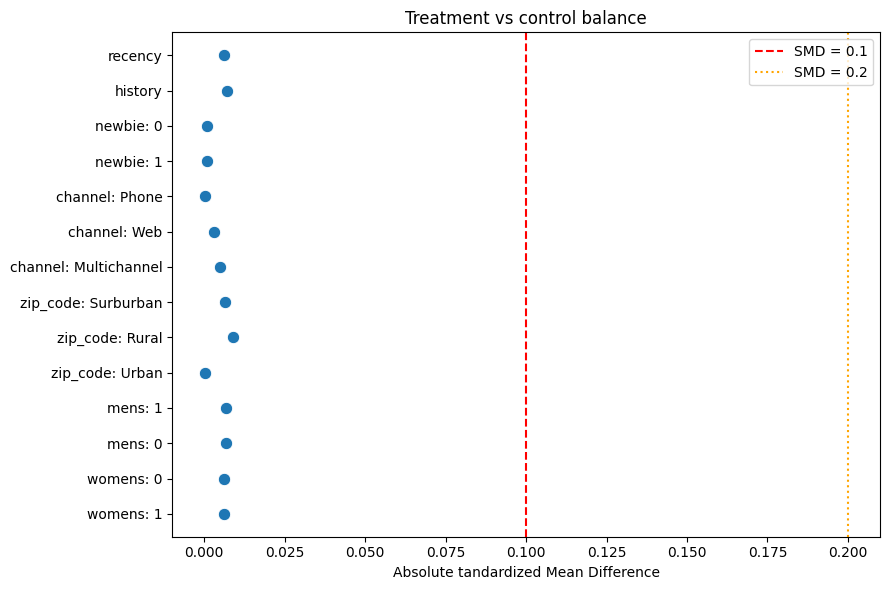

In [16]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=smd_df,
    x='smd',
    y='feature',
    s=80
)

plt.axvline(0.1, linestyle='--', color='red', label='SMD = 0.1')
plt.axvline(0.2, linestyle=':', color='orange', label='SMD = 0.2')

plt.xlabel('Absolute tandardized Mean Difference')
plt.ylabel('')
plt.title('Treatment vs control balance')
plt.legend()
plt.tight_layout()
plt.show()

## Estimate lift
How much did the email change visits, conversions and spend, and how sure are we?

I'll be comparing
Primary: any email (Men’s + Women’s combined) vs. control
Secondary: Men’s vs. control, and Women’s vs. control
Bonus: Men’s vs. Women’s

In [17]:
hillstrom['segment'].unique()

array(['Womens E-Mail', 'No E-Mail', 'Mens E-Mail'], dtype=object)

In [ ]:
df = hillstrom.copy()

df["any_email"] = (df["segment"] != "No E-Mail").astype(int)

In [22]:
# # Check visit, conversion, and spend

# treatment = df[df['any_email'] == 1]
# control = df[df['any_email'] == 0]

# # conversion rates
# treatment_rate = treatment['conversion'].mean()
# control_rate = control['conversion'].mean()

# print(f'Treatment conversation rate: {treatment_rate:.2%}')
# print(f'Control conversation rate: {control_rate:.2%}')


# absolute_lift = treatment_rate - control_rate # the difference in conversion rates
# relative_lift = absolute_lift / control_rate # percentage increase or decrease of sending an email compared to not sending one

# print(f"Absolute lift: {absolute_lift:.2%}")
# print(f"Relative lift: {relative_lift:.2%}")

# # Sending an email increased the conversion rate by 0.50 percentage points, representing an 86.53% relative increase compared with sending no email.

Treatment conversation rate: 1.07%
Control conversation rate: 0.57%
Absolute lift: 0.50%
Relative lift: 86.53%


Is this statistically significant?
I'll use the z-test to find out if the difference in conversion rates between the treatment and control groups is significant.

The test looks at three things:
1. The conversion rate in the treatment group.
2. The conversion rate in the control group.
3. The standard error of the difference between those rates.
It then calculates a z-statistic:
$$
z = \frac{\hat p_T-\hat p_C}{SE}
$$
The z-statistic tells us how many standard errors the observed difference is away from zero.

A large absolute z-statistic suggests stronger evidence that the conversion rates differ.

The $h_0$ is that sending the email has no effect on the conversion rate. So if the p_value is > 0.05 we fail to reject.

In [55]:
### Spend lift

lift_cols = ['visit', 'conversion', 'spend']

def calculate_lift(col):
    # conversion rates
    treatment_average = treatment[col].mean()
    control_average = control[col].mean()

    absolute_lift = treatment_average - control_average # the difference in conversion rates
    relative_lift = absolute_lift / control_average # percentage increase or decrease of sending an email compared to not sending one

    
    if (col == 'conversion' or col == 'visit'):
        print(f'Treatment {col} average: {treatment_average:.2%}')
        print(f'Control {col} average: {control_average:.2%}')
        print(f"Absolute {col} lift: {absolute_lift:.2%}")
        print(f"Relative {col} lift: {relative_lift:.2%}")
            
    else:
        print(f'Treatment {col} average: {treatment_average:.2f}')
        print(f'Control {col} average: {control_average:.2f}')
        print(f"Absolute {col} lift: {absolute_lift:.2f}")
        print(f"Relative {col} lift: {relative_lift:.2f}")
            

def z_test_binary(col):
    treatment_sum = treatment[col].sum()
    control_sum = control[col].sum()
    treatment_n = len(treatment)
    control_n = len(control)

    counts = [
        treatment_sum, control_sum
    ]

    nobs = [
        len(treatment),
        len(control)
    ]

    z_stat, p_value = proportions_ztest(
        counts,
        nobs,
        alternative='two-sided'
    )

    print(f"Z-statistic: {z_stat:.4f}")
    print(f"P-value: {p_value}") # p_value is less than 0.05 so we reject the null hypothesis.

    ci_low, ci_high = confint_proportions_2indep(
        treatment_sum,
        treatment_n,
        control_sum,
        control_n,
        method='newcomb'
    )

    print(f"95% CI: [{ci_low:.2%}, {ci_high:.2%}]")



# two sample t-test /null hypothesis is average spending is equal
# Welch's two-sample t-test for continuous variables

def t_test_continuous(col):

    treatment_values = treatment[col]
    control_values = control[col]

    # Calculate difference in means
    mean_diff = treatment_values.mean() - control_values.mean()

    # Welch's t-test
    t_stat, p_value = ttest_ind(
        treatment_values,
        control_values,
        equal_var=False
    )

    # Calculate standard error
    se = np.sqrt(
        treatment_values.var(ddof=1) / len(treatment_values) +
        control_values.var(ddof=1) / len(control_values)
    )

    # Welch-Satterthwaite degrees of freedom
    var_t = treatment_values.var(ddof=1) / len(treatment_values)
    var_c = control_values.var(ddof=1) / len(control_values)

    df_welch = (var_t + var_c)**2 / (
        var_t**2 / (len(treatment_values) - 1) +
        var_c**2 / (len(control_values) - 1)
    )

    # 95% confidence interval
    critical_value = t.ppf(0.975, df_welch)

    ci_low = mean_diff - critical_value * se
    ci_high = mean_diff + critical_value * se

    print(f"Treatment mean {col}: {treatment_values.mean():.2f}")
    print(f"Control mean {col}: {control_values.mean():.2f}")
    print(f"Mean difference {col}: {mean_diff:.2f}")
    print(f"T-statistic {col}: {t_stat:.4f}")
    print(f"P-value {col}: {p_value:.6f}")
    print(f"95% CI {col}: [{ci_low:.2f}, {ci_high:.2f}]")


In [49]:
calculate_lift('conversion')
z_test_binary('conversion')


Treatment conversion average: 1.07%
Control conversion average: 0.57%
Absolute conversion lift: 0.50%
Relative conversion lift: 86.53%
Z-statistic: 6.2438
P-value: 4.271613795144971e-10
95% CI: [0.35%, 0.63%]


In [50]:

calculate_lift('spend')
t_test_continuous('spend')


Treatment spend average: 1.25
Control spend average: 0.65
Absolute spend lift: 0.60
Relative spend lift: 0.91
Treatment mean spend: 1.25
Control mean spend: 0.65
Mean difference spend: 0.60
T-statistic spend: 5.3022
P-value spend: 0.000000
95% CI spend: [0.38, 0.82]


In [56]:
calculate_lift('visit')
z_test_binary('visit')

Treatment visit average: 16.70%
Control visit average: 10.62%
Absolute visit lift: 6.09%
Relative visit lift: 57.35%
Z-statistic: 20.5101
P-value: 1.7497869967580046e-93
95% CI: [5.54%, 6.63%]


# Calculate profit across the email cost range
The dataset has no profit margin so I'm assuming a 40%

$$Profit = (Spend\ Lift \times Margin) - Email\ Cost$$

At break-even, profit=0
$$0 = (Spend\ Lift \times Margin) - Email\ Cost$$

If you rearrange this equation:
$$Email\ Cost = Spend\ Lift \times Margin$$

At the point estimate, 0.60, the email cost is $0.60 \times 0.40 = 0.24$
But we also have the CIs.

| Scenario | Spend lift | Margin | Break-even email cost |
|---|---:|---:|---:|
| Lower bound | 0.38 | 40% | 0.152 |
| Point estimate | 0.60 | 40% | 0.240 |
| Upper bound | 0.82 | 40% | 0.328 |

In [63]:
# Inputs
lift_low = 0.38
lift_point = 0.60
lift_high = 0.82

margin = 0.40

# Gonna use email costs between 0.001 and 1 dollar
email_costs = np.geomspace(0.0001, 1.00, 100)

results = pd.DataFrame({
    'email_cost': email_costs,
    'profit_low': (lift_low * margin) - email_costs,
    'profit_point': (lift_point * margin) - email_costs,
    'profit_high': (lift_high * margin) - email_costs
})

results.head()

,email_cost,profit_low,profit_point,profit_high
0,0.000100,0.151900,0.239900,0.327900
1,0.000110,0.151890,0.239890,0.327890
2,0.000120,0.151880,0.239880,0.327880
3,0.000132,0.151868,0.239868,0.327868
4,0.000145,0.151855,0.239855,0.327855


In [64]:
# to break even the email costs must be

break_even_low = lift_low * margin
break_even_point = lift_point * margin
break_even_high = lift_high * margin

print(f"Lower-bound break-even: {break_even_low:.3f}")
print(f"Point-estimate break-even: {break_even_point:.3f}")
print(f"Upper-bound break-even: {break_even_high:.3f}")

Lower-bound break-even: 0.152
Point-estimate break-even: 0.240
Upper-bound break-even: 0.328


Break-even range: $0.152 to $0.328 (point: $0.240)


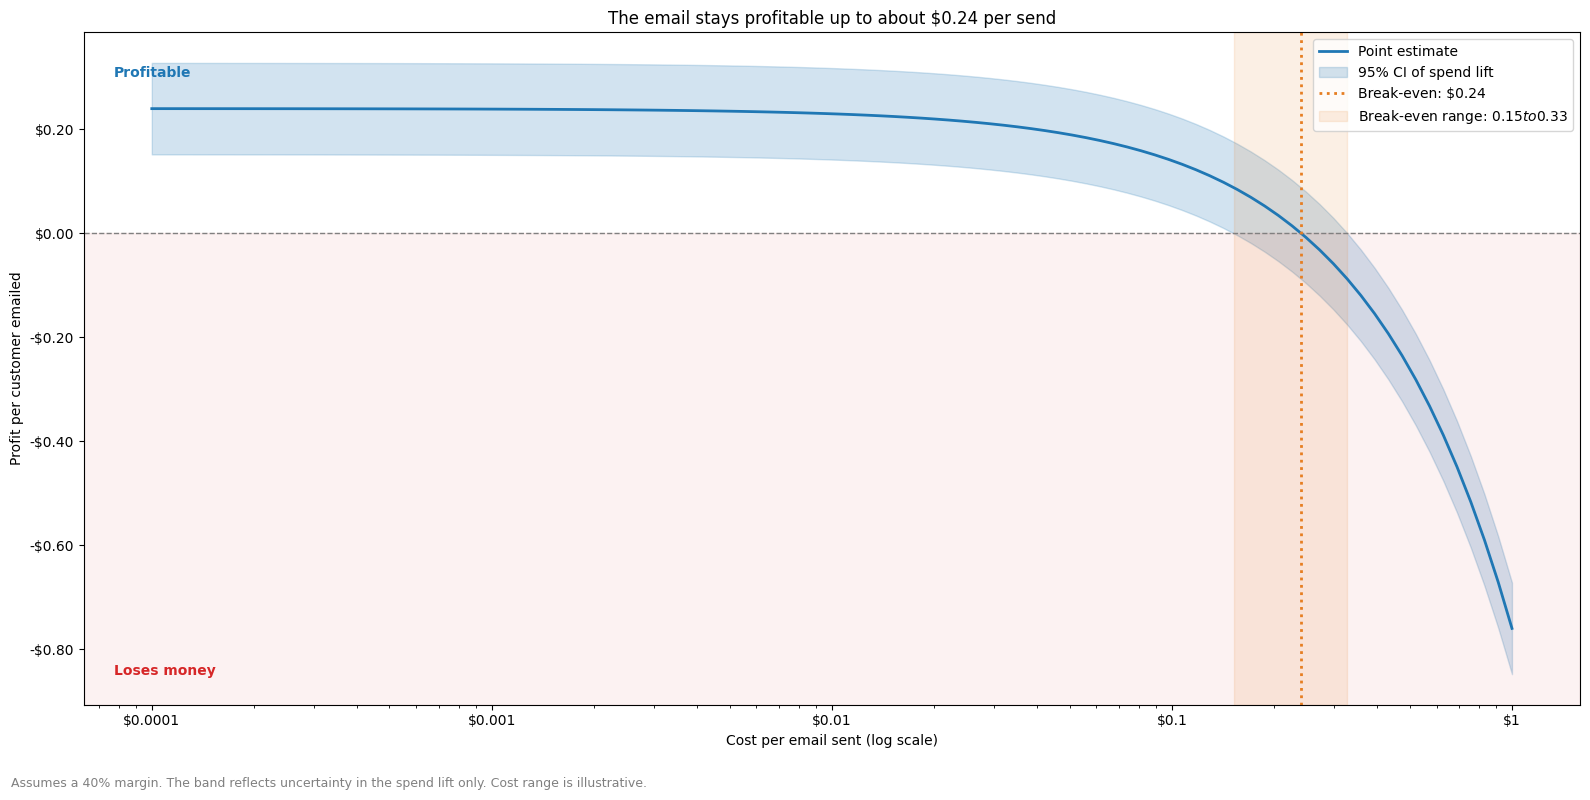

In [66]:
from matplotlib.ticker import FuncFormatter, NullFormatter

MARGIN = 0.40

# Break-even for the low and high scenarios (profit + cost = lift x margin)
be_low = (results['profit_low'] + results['email_cost']).iloc[0]
be_high = (results['profit_high'] + results['email_cost']).iloc[0]
print(f"Break-even range: ${be_low:.3f} to ${be_high:.3f} (point: ${break_even_point:.3f})")

plt.figure(figsize=(16, 8))

# Point estimate
plt.plot(
    results['email_cost'],
    results['profit_point'],
    color='#1f77b4',
    label='Point estimate',
    linewidth=2
)

# Confidence interval band
plt.fill_between(
    results['email_cost'],
    results['profit_low'],
    results['profit_high'],
    color='#1f77b4',
    alpha=0.2,
    label='95% CI of spend lift'
)

# Zero-profit reference line
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

# Tint the loss region
ymin, ymax = plt.ylim()
plt.axhspan(ymin, 0, color='#d62728', alpha=0.06)
plt.ylim(ymin, ymax)

# Break-even point and range
plt.axvline(
    break_even_point,
    color='#e67e22',
    linestyle=':',
    linewidth=2,
    label=f'Break-even: ${break_even_point:.2f}'
)
plt.axvspan(
    be_low, be_high,
    color='#e67e22',
    alpha=0.12,
    label=f'Break-even range: ${be_low:.2f} to ${be_high:.2f}'
)

# Zone labels
plt.text(0.02, 0.95, 'Profitable', transform=plt.gca().transAxes,
         va='top', color='#1f77b4', fontweight='bold')
plt.text(0.02, 0.04, 'Loses money', transform=plt.gca().transAxes,
         va='bottom', color='#d62728', fontweight='bold')

# Log scale with dollar labels
plt.xscale('log')
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'${x:g}'))
plt.gca().xaxis.set_minor_formatter(NullFormatter())
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f'-${abs(y):.2f}' if y < 0 else f'${y:.2f}'))

plt.xlabel('Cost per email sent (log scale)')
plt.ylabel('Profit per customer emailed')
plt.title(f'The email stays profitable up to about ${break_even_point:.2f} per send')

plt.legend(loc='upper right')
plt.grid(False)

# Caption
plt.figtext(
    0.01, 0.01,
    f"Assumes a {MARGIN:.0%} margin. The band reflects uncertainty in the spend lift only. "
    "Cost range is illustrative.",
    fontsize=9, color='gray', ha='left'
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig('assets/outputs/profit_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()